In [39]:
import requests 
from bs4 import BeautifulSoup 
import pandas as pd

import matplotlib.pyplot as plt 
import seaborn as sns 

In [40]:
url = "https://steam250.com/discounts"

headers = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/150.0.0.0 Safari/537.36"
}

In [41]:
response = requests.get(url, headers = headers)
response

<Response [200]>

In [42]:
soup = BeautifulSoup(response.text, "html.parser")

In [45]:
names = soup.select("div.title > div > a")
sources = soup.select("div.title > div:nth-child(2) > a")
scores = soup.select("div.score.stat")
reviews = soup.select("div.reviews.stat > span")
prices = soup.select("div.price.stat > span")  

In [46]:
row = []

for name,source,score,review,price in zip(names,sources,scores,reviews,prices):
    row.append({
        "names":name.get_text(strip=True),
        "sources":source.get_text(strip=True),
        "scores":score.get_text(strip=True), 
        "reviews":review.get_text(strip=True), 
        "prices": price.get_text(strip=True)
    })

In [47]:
df = pd.DataFrame(row)
df.head()

,names,sources,scores,reviews,prices
0,The Forest,Open World Survival Craft,9.81,"686,101",$3.99
1,Open World Survival Craft,Open World Survival Craft,9.81,"382,769",$19.99
2,Subnautica,FPS,9.81,"381,518",$7.49
3,Open World Survival Craft,Colony Sim,9.79,"249,199",$29.99
4,Deep Rock Galactic,Survival Horror,9.78,"285,886",$8.99


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   names    250 non-null    str  
 1   sources  250 non-null    str  
 2   scores   250 non-null    str  
 3   reviews  250 non-null    str  
 4   prices   250 non-null    str  
dtypes: str(5)
memory usage: 20.7 KB


In [49]:
df["scores"] = df["scores"].astype(float)

df["reviews"] = df["reviews"].str.replace(",","")
df["reviews"] = df["reviews"].astype(int)

df["prices"] = df["prices"].str.replace("$","")
df["prices"] = df["prices"].astype(float) 

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   names    250 non-null    str    
 1   sources  250 non-null    str    
 2   scores   250 non-null    float64
 3   reviews  250 non-null    int64  
 4   prices   250 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 16.9 KB


In [50]:
df.head(4)

,names,sources,scores,reviews,prices
0,The Forest,Open World Survival Craft,9.81,686101,3.99
1,Open World Survival Craft,Open World Survival Craft,9.81,382769,19.99
2,Subnautica,FPS,9.81,381518,7.49
3,Open World Survival Craft,Colony Sim,9.79,249199,29.99


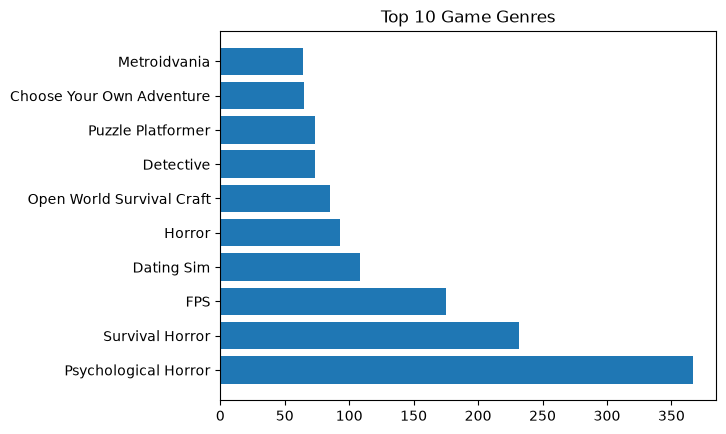

In [58]:
mf = df.groupby('sources').agg({"scores":"sum"}).reset_index().sort_values("scores",ascending = False ).head(10) 

plt.barh(mf['sources'],mf['scores'])
plt.title("Top 10 Game Genres")
plt.show()

In [38]:
df.to_csv("game.csv", index = False)
print("done")

done
